# 06 · Science and technology: gender differences (thesis chapter 4)

Replication of the application of chapter 4 of the thesis [`lavado2012phd`]: 11 continuous indicators for 15 EU countries,
analysed by PCA and by qlPCA with linear splines and one or two interior knots. The data are those of Oliveira & Carvalho
[`oliveira2009segmentation`], built from Eurostat and *She Figures 2006* [`ec2006shefigures`]; see `data/README.md`.

> **This is the exact replication of the repository.** The thesis tables (4.1, 4.3–4.8) are compared number by number, with
> the tolerance of 0.005 for the qlPCA tables, using `legacy=True` (the behaviour of the 2012 MATLAB code). Loadings are compared in absolute
> value or after aligning signs, because their sign is a convention (docs/SPEC.md §8). What is *not* exactly reproduced is stated explicitly (§6).

*Contents:* 1. data and summary statistics (Table 4.1) · 2. correlations and PCA (Tables 4.2–4.4, Fig. 4.1) · 3. qlPCA (Tables 4.5–4.8) ·
4. scree plots and the number of components (Figs 4.2–4.5) · 5. optimal transformations (Figs 4.6–4.7) · 6. the local optimum of Fig. 4.5 ·
7. biplots (Figs 4.8–4.10) · 8. piecewise loadings · 9. summary of the comparison with the thesis · References.

In [1]:
import json, pathlib, collections, itertools
import numpy as np
import matplotlib.pyplot as plt
from qlpca import QLPCA
from qlpca.datasets import load_st_gender
from qlpca.diagnostics import communalities, piecewise_loadings, vaf_percent
from qlpca.plots import set_style, scree_plot, transformation_plots, biplot, BLUE, ORANGE, INK, INK2, GRID

set_style()
np.set_printoptions(precision=3, suppress=True, linewidth=130)
X, names, countries = load_st_gender()
n, m = X.shape
ref = json.load(open(pathlib.Path("..") / "tests" / "reference_values.json", encoding="utf8"))
assert names == ref["variables"]
TOL = 0.005
SUMMARY = {}                      # collected for section 9

## 1 · Data and summary statistics

Fifteen countries (the 27 EU members minus twelve with missing values: Austria, Bulgaria, Cyprus, France, Greece, Ireland, Luxembourg, Malta, Portugal, Romania,
Spain, United Kingdom). Six values carry a third decimal that was added in the thesis so that every value within a variable is unique, which the 2012
implementation required (data/README.md); they are kept.

In [2]:
t41 = ref["table_4_1_summary"]
stats = {"min": X.min(0), "max": X.max(0), "mean": X.mean(0), "std": X.std(0, ddof=1), "median": np.median(X, 0)}
print("variable             " + "   ".join(f"{k:>7s}" for k in stats))
for j, nm in enumerate(names):
    print(f"{nm:20s} " + "   ".join(f"{stats[k][j]:7.2f}" for k in stats))
d = {k: np.abs(stats[k] - np.array(t41[k])).max() for k in stats}
print("\nmax |difference| to thesis Table 4.1:", {k: round(v, 3) for k, v in d.items()})
SUMMARY["Table 4.1 (summary statistics)"] = max(d.values())

variable                 min       max      mean       std    median
researchers             4.50     18.87      8.58      4.26      6.37
scientists_engineers    2.50      7.70      4.83      1.73      4.50
investment             14.12    169.72     75.36     51.03     71.04
mf_funds               -4.75      6.10      1.20      3.75      1.09
w_top                   1.80     16.50      5.82      3.91      4.20
m_top                   9.80     38.30     19.42      7.32     17.80
glass_ceiling           1.70      3.20      2.27      0.48      2.20
mf_phd                -34.38     29.50      6.15     19.51     14.15
mf_researchers         -6.15     65.65     31.97     19.70     31.22
mf_teaching           -15.46     41.69     23.53     16.76     30.11
mf_boards               4.92     85.61     56.20     24.53     59.46

max |difference| to thesis Table 4.1: {'min': np.float64(0.0), 'max': np.float64(0.0), 'mean': np.float64(0.02), 'std': np.float64(0.005), 'median': np.float64(0.001)}


The only difference larger than 0.005 is the mean of `m_top` (19.42 against 19.4 printed): the thesis rounds it to the precision of the column.

## 2 · Correlations and PCA (Tables 4.2–4.4, Figure 4.1)

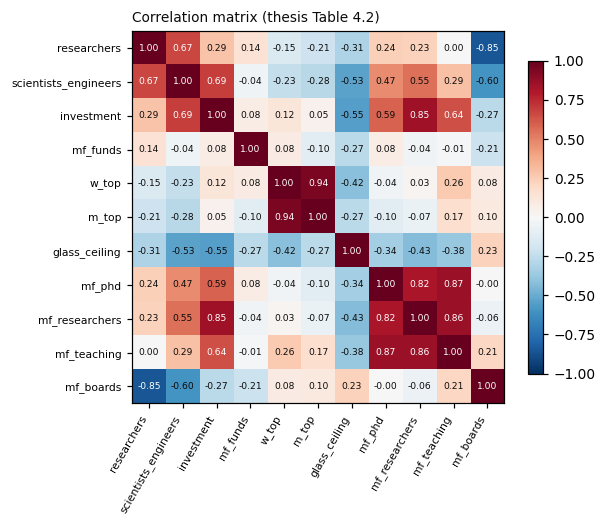

corr(researchers, mf_boards) = -0.85   (thesis Table 4.2: -0.85)
corr(m_top, w_top) = 0.94   (thesis Table 4.2: 0.94)
corr(investment, mf_researchers) = 0.85   (thesis Table 4.2: 0.85)
corr(mf_phd, mf_teaching) = 0.87   (thesis Table 4.2: 0.87)


In [3]:
R = np.corrcoef(X.T)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(m)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(m)); ax.set_yticklabels(names, fontsize=7)
for i in range(m):
    for j in range(m):
        ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(R[i, j]) > 0.6 else INK)
ax.set_title("Correlation matrix (thesis Table 4.2)", loc="left", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

# values quoted in the text of section 4.2.1 (|r| > 0.66 'strong')
for a, b, quoted in (("researchers", "mf_boards", -0.85), ("m_top", "w_top", 0.94), ("investment", "mf_researchers", 0.85), ("mf_phd", "mf_teaching", 0.87)):
    print(f"corr({a}, {b}) = {R[names.index(a), names.index(b)]:.2f}   (thesis Table 4.2: {quoted})")

component  eigenvalue (computed / thesis)   % variance (computed / thesis)   cumulative % (computed / thesis)
     1        4.276 /  4.276              38.87 /  38.87              38.87 /  38.87
     2        2.532 /  2.531              23.01 /  23.01              61.89 /  61.89
     3        1.878 /  1.878              17.07 /  17.07              78.96 /  78.96
     4        1.037 /  1.037               9.43 /   9.43              88.38 /  88.39
     5        0.574 /  0.574               5.22 /   5.22              93.60 /  93.60
     6        0.387 /  0.387               3.52 /   3.52              97.12 /  97.12
     7        0.148 /  0.148               1.35 /   1.35              98.47 /  98.47
     8        0.071 /  0.071               0.64 /   0.64              99.11 /  99.11
     9        0.055 /  0.055               0.50 /   0.50              99.61 /  99.61
    10        0.027 /  0.027               0.24 /   0.24              99.85 /  99.85
    11        0.017 /  0.017            

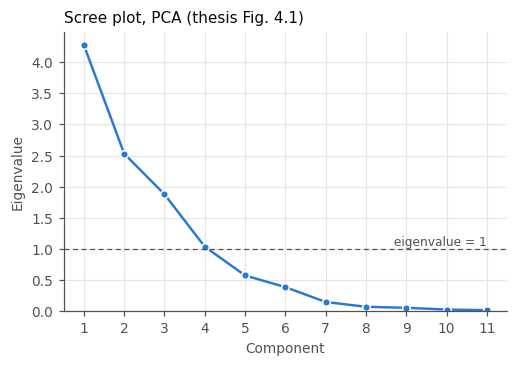

In [4]:
ev = np.linalg.eigvalsh(R)[::-1]
t43 = ref["table_4_3_pca"]
print("component  eigenvalue (computed / thesis)   % variance (computed / thesis)   cumulative % (computed / thesis)")
for s in range(m):
    print(f"{s + 1:6d}    {ev[s]:9.3f} / {t43['eigenvalues'][s]:6.3f}          {100 * ev[s] / m:9.2f} / {t43['pct_variance'][s]:6.2f}          "
          f"{100 * ev[:s + 1].sum() / m:9.2f} / {t43['cumulative_pct'][s]:6.2f}")
dd = np.abs(ev - t43["eigenvalues"]).max()
print("\nmax |eigenvalue difference|:", round(dd, 4), "(the thesis prints three decimals)")
SUMMARY["Table 4.3 (PCA eigenvalues)"] = dd

pca4 = QLPCA(4, degree=1, n_knots=0).fit(X)
t44 = np.abs(np.array(ref["table_4_4_pca_loadings"]))
dl = np.abs(np.abs(pca4.loadings_) - t44).max()
print("PCA, 4 components: max ||loading| - thesis Table 4.4| =", round(dl, 3), "(thesis prints two decimals)")
SUMMARY["Table 4.4 (PCA loadings, |.|)"] = dl
j = names.index("mf_funds")
pca2 = QLPCA(2, degree=1, n_knots=0).fit(X)
print("PCA communality of mf_funds in 2 components: %.4f from the exact loadings; %.4f from the two-decimal loadings of Table 4.4 (thesis: 0.0244)"
      % (pca2.communalities_[j], 0.12 ** 2 + 0.10 ** 2))

fig, ax = plt.subplots(figsize=(5.2, 3.3))
scree_plot(ev, ax=ax, title="Scree plot, PCA (thesis Fig. 4.1)")
plt.show()

The eigenvalue criterion and the scree plot suggest four components (eigenvalue above 1, break at the fifth component), and two components explain 61.89 % — the
motivation in the thesis for looking at nonlinear variants.

## 3 · qlPCA with linear splines (Tables 4.5–4.8)

Degree 1, one or two interior knots, two components, with `legacy=True`.

In [5]:
leg = {k: QLPCA(2, degree=1, n_knots=r, legacy=True).fit(X) for k, r in (("qlpca1", 1), ("qlpca2", 2))}
dflt = {k: QLPCA(2, degree=1, n_knots=r, random_state=0).fit(X) for k, r in (("qlpca1", 1), ("qlpca2", 2))}

print("Table 4.5: eigenvalues and % variance")
for k in leg:
    t = ref["table_4_5_qlpca"][k]
    print(f"  {k}: eigenvalues {leg[k].eigenvalues_} (thesis {t['eigenvalues']}) | %VAF {vaf_percent(leg[k].loadings_)} (thesis {t['pct_variance']}) "
          f"| total {100 * leg[k].eigenvalues_.sum() / m:.2f} (thesis {t['total_pct']})")
    SUMMARY[f"Table 4.5 {k} (eigenvalues)"] = np.abs(leg[k].eigenvalues_ - t["eigenvalues"]).max()
    SUMMARY[f"Table 4.6 {k} (|loadings|)"] = np.abs(np.abs(leg[k].loadings_) - np.abs(ref["table_4_6_loadings"][k])).max()
    SUMMARY[f"Tables 4.7/4.8 {k} (communalities)"] = np.abs(leg[k].communalities_ - ref["communalities"][k]).max()
print("\nthe default estimator gives the same optimum here:",
      {k: round(100 * dflt[k].eigenvalues_.sum() / m, 2) for k in dflt})

Table 4.5: eigenvalues and % variance
  qlpca1: eigenvalues [4.582 2.998] (thesis [4.582, 2.998]) | %VAF [41.651 27.251] (thesis [41.65, 27.25]) | total 68.90 (thesis 68.9)
  qlpca2: eigenvalues [4.759 3.637] (thesis [4.76, 3.637]) | %VAF [43.265 33.063] (thesis [43.27, 33.06]) | total 76.33 (thesis 76.33)

the default estimator gives the same optimum here: {'qlpca1': np.float64(68.9), 'qlpca2': np.float64(76.33)}


**Loadings (Table 4.6) and communalities (Tables 4.7, 4.8).** Signs are a convention. The package orients each transformed variable so that
$\operatorname{corr}(f_j,h_j)\ge0$ and each component so that its largest loading is positive (DESIGN D6); the thesis signs come from MATLAB. To compare
loadings the table below aligns the signs to the thesis: first each component, then — where a variable still disagrees — the whole row of that variable
(possible because $-f_j$ is as admissible as $f_j$ when the transformation is not monotone). The rows that had to be flipped are listed.

In [6]:
def align_to(thesis, A):
    # presentation helper: flip components, then rows, to agree in sign with the thesis loadings
    A = A.copy(); c = np.sign((thesis * A).sum(0)); c[c == 0] = 1; A = A * c
    r = np.sign((thesis * A).sum(1)); r[r == 0] = 1
    return A * r[:, None], c, r

for k, rr in (("qlpca1", 1), ("qlpca2", 2)):
    th = np.array(ref["table_4_6_loadings"][k]); A, c, r = align_to(th, leg[k].loadings_)
    print(f"\n=== {k} (r = {rr}): loadings aligned to the thesis | thesis | communality computed / thesis ===")
    for j, nm in enumerate(names):
        print(f"{nm:16s} {A[j]}  |  {th[j]}   {leg[k].communalities_[j]:.2f} / {ref['communalities'][k][j]:.2f}")
    print("components flipped:", [int(s + 1) for s in np.flatnonzero(c < 0)], "| variables flipped:", [names[j] for j in np.flatnonzero(r < 0)])
    print("max |aligned loading - thesis| =", np.abs(A - th).max().round(3), "| max |communality - thesis| =", np.abs(leg[k].communalities_ - ref["communalities"][k]).max().round(3))


=== qlpca1 (r = 1): loadings aligned to the thesis | thesis | communality computed / thesis ===
researchers      [-0.531  0.702]  |  [-0.53  0.7 ]   0.77 / 0.77
scientists_engineers [-0.717  0.554]  |  [-0.72  0.55]   0.82 / 0.82
investment       [-0.939 -0.076]  |  [-0.94 -0.08]   0.89 / 0.89
mf_funds         [-0.087  0.489]  |  [-0.09  0.49]   0.25 / 0.25
w_top            [-0.227 -0.755]  |  [-0.23 -0.75]   0.62 / 0.62
m_top            [-0.309 -0.754]  |  [-0.31 -0.75]   0.66 / 0.66
glass_ceiling    [ 0.668 -0.071]  |  [ 0.67 -0.07]   0.45 / 0.45
mf_phd           [-0.827 -0.113]  |  [-0.83 -0.11]   0.70 / 0.70
mf_researchers   [-0.918 -0.192]  |  [-0.92 -0.19]   0.88 / 0.88
mf_teaching      [-0.791 -0.495]  |  [-0.79 -0.49]   0.87 / 0.87
mf_boards        [ 0.387 -0.718]  |  [ 0.39 -0.72]   0.67 / 0.67
components flipped: [1, 2] | variables flipped: []
max |aligned loading - thesis| = 0.005 | max |communality - thesis| = 0.005

=== qlpca2 (r = 2): loadings aligned to the thesis | the

Everything in Tables 4.5–4.8 is reproduced within the printed precision (maximum difference 0.005, i.e. rounding of the two-decimal tables). The one-knot solution has
$\text{VAF}=68.90\,\%$ and the two-knot solution $76.33\,\%$, against $61.89\,\%$ for PCA. The communality of `mf_funds` rises from 0.0244 (PCA) to 0.25 (one knot) and
0.80 (two knots), the largest change of any variable.

## 4 · Scree plots and the number of components (Figures 4.2–4.5)

qlPCA solutions are not nested, so each scree plot refers to one value of $p$. Thesis: with one knot and $p=2$ the break is at the third component, with $p=3$ at the fourth —
no consistent location, so the choice between two and three components cannot be made from the scree plot; the two-knot solutions are the same.

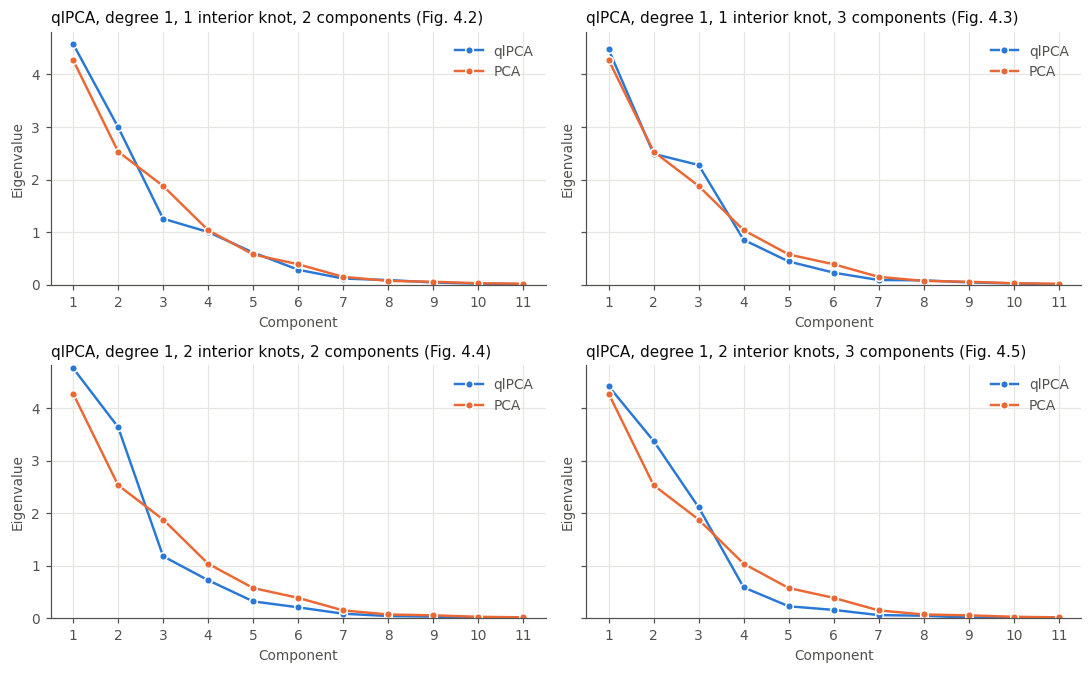

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharey=True)
for ax, (r, p, fig_no) in zip(axes.flat, ((1, 2, "4.2"), (1, 3, "4.3"), (2, 2, "4.4"), (2, 3, "4.5"))):
    mdl = QLPCA(p, degree=1, n_knots=r, legacy=True).fit(X)
    scree_plot(mdl, ax=ax, reference=ev, reference_label="PCA", label="qlPCA", kaiser=False,
               title=f"qlPCA, degree 1, {r} interior knot{'s' if r > 1 else ''}, {p} components (Fig. {fig_no})")
plt.tight_layout(); plt.show()

## 5 · Optimal transformations (Figures 4.6 and 4.7)

The transformed variables $f_j$ against the standardised original variables (here in original units), for one and two interior knots. The interior knots are at the median
(Fig. 4.6) and at the 33rd and 67th percentiles (Fig. 4.7), marked by dashed lines.

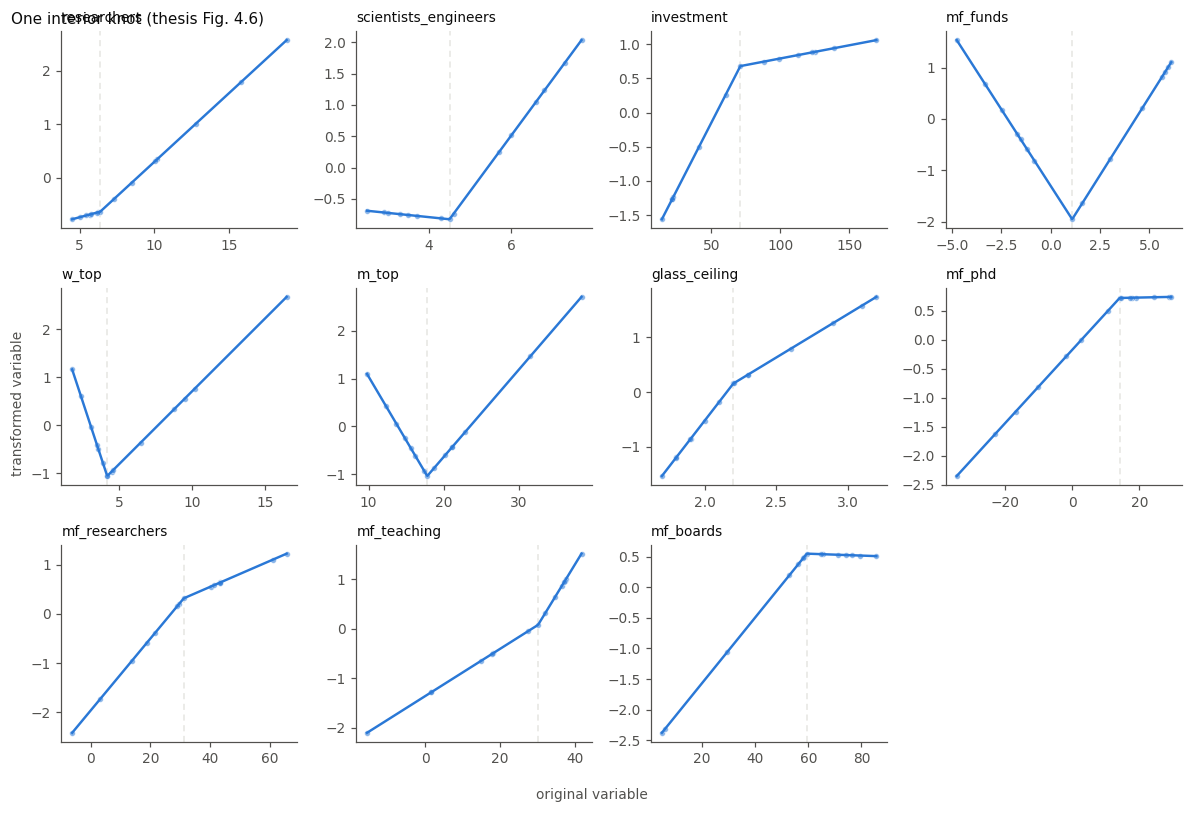

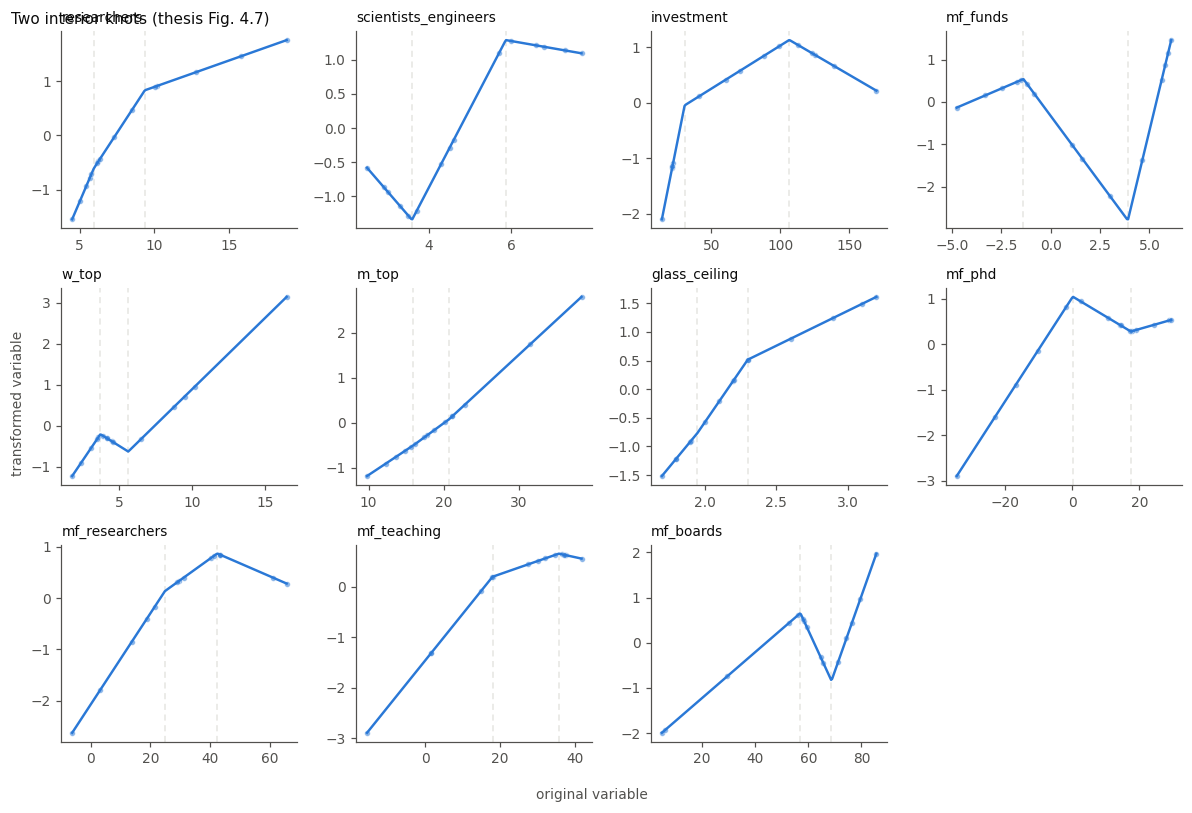

In [8]:
m1 = QLPCA(2, degree=1, n_knots=1, random_state=0).fit(X)
m2 = QLPCA(2, degree=1, n_knots=2, random_state=0).fit(X)
transformation_plots(m1, X, names, ncols=4, figsize=(11, 7.4)); plt.suptitle("One interior knot (thesis Fig. 4.6)", x=0.02, ha="left", fontsize=10); plt.show()
transformation_plots(m2, X, names, ncols=4, figsize=(11, 7.4)); plt.suptitle("Two interior knots (thesis Fig. 4.7)", x=0.02, ha="left", fontsize=10); plt.show()

The thesis describes the shapes in the one-knot solution: `researchers` and `glass_ceiling` are close to linear; `scientists_engineers`, `mf_phd` and `mf_boards` have one nearly horizontal segment;
`mf_funds`, `w_top` and `m_top` are V-shaped; `investment`, `mf_researchers` and `mf_teaching` are monotone with a marked change of slope at the median. The cell classifies each transformation
by the slopes of its two segments to check these statements (orientation-free: only the ratio and relative sign of the slopes matter).

In [9]:
def classify(model, j):
    x, f = model.variable_transformation(j, 400)
    med = np.unique(model.knots_[j])[1] * model.std_[j] + model.mean_[j]      # the interior knot
    a, b, c = x[0], med, x[-1]
    fa, fb, fc = np.interp([a, b, c], x, f)
    s1, s2 = (fb - fa) / (b - a) * model.std_[j], (fc - fb) / (c - b) * model.std_[j]  # slopes per standard deviation
    lo, hi = sorted((abs(s1), abs(s2)))
    if lo < 0.2 * hi: return "one nearly horizontal segment", s1, s2
    if s1 * s2 < 0: return "V-shaped", s1, s2
    if hi < 1.6 * lo: return "close to linear", s1, s2
    return "monotone, marked change of slope", s1, s2

thesis_text = {"researchers": "close to linear", "glass_ceiling": "close to linear",
               "scientists_engineers": "one nearly horizontal segment", "mf_phd": "one nearly horizontal segment", "mf_boards": "one nearly horizontal segment",
               "mf_funds": "V-shaped", "w_top": "V-shaped", "m_top": "V-shaped",
               "investment": "monotone, marked change of slope", "mf_researchers": "monotone, marked change of slope", "mf_teaching": "monotone, marked change of slope"}
agree = 0
for j, nm in enumerate(names):
    kind, s1, s2 = classify(m1, j)
    agree += kind == thesis_text[nm]
    print(f"{nm:20s} slopes {s1:6.2f} {s2:6.2f}   {kind:34s} thesis: {thesis_text[nm]:34s} {'ok' if kind == thesis_text[nm] else '<-- differs'}")
print(f"\nagreement with the thesis description (Fig. 4.6): {agree} of {m} variables")

researchers          slopes   0.32   1.09   monotone, marked change of slope   thesis: close to linear                    <-- differs
scientists_engineers slopes  -0.11   1.54   one nearly horizontal segment      thesis: one nearly horizontal segment      ok
investment           slopes   2.01   0.20   one nearly horizontal segment      thesis: monotone, marked change of slope   <-- differs
mf_funds             slopes  -2.24   2.29   V-shaped                           thesis: V-shaped                           ok
w_top                slopes  -3.59   1.18   V-shaped                           thesis: V-shaped                           ok
m_top                slopes  -1.95   1.34   V-shaped                           thesis: V-shaped                           ok
glass_ceiling        slopes   1.62   0.76   monotone, marked change of slope   thesis: close to linear                    <-- differs
mf_phd               slopes   1.24   0.03   one nearly horizontal segment      thesis: one nearly 

The classification uses thresholds chosen here (slope ratio below 0.2 for "horizontal", below 1.6 for "close to linear"; a segment with a near-zero slope counts as horizontal before the signs are compared), so it is a rough check of the thesis's visual description, not a replication of a number, and the thresholds were not tuned to the thesis. The variables on which it still differs are judgement calls about how much curvature counts as "close to linear" or as "horizontal"; the slope ratios printed above and the transformations in the figure are the evidence.

With two knots the thesis observes that the extra flexibility is used mainly by `scientists_engineers`, `mf_funds` and `mf_boards`, and that the communality of `mf_funds`
increases from 0.25 to 0.80 while those of `scientists_engineers` and `mf_boards` stay about the same.

In [10]:
print("communality   variable            PCA (2)   qlPCA 1 knot   qlPCA 2 knots")
for j, nm in enumerate(names):
    print(f"              {nm:18s}  {pca2.communalities_[j]:6.2f}   {leg['qlpca1'].communalities_[j]:10.2f}   {leg['qlpca2'].communalities_[j]:12.2f}")
print("\nminimum communality: 1 knot %.2f (thesis: >= 0.25), 2 knots %.2f (thesis: >= 0.33)" % (leg['qlpca1'].communalities_.min(), leg['qlpca2'].communalities_.min()))

communality   variable            PCA (2)   qlPCA 1 knot   qlPCA 2 knots
              researchers           0.66         0.77           0.79
              scientists_engineers    0.83         0.82           0.89
              investment            0.79         0.89           0.90
              mf_funds              0.03         0.25           0.80
              w_top                 0.60         0.62           0.77
              m_top                 0.58         0.66           0.66
              glass_ceiling         0.47         0.45           0.33
              mf_phd                0.67         0.70           0.91
              mf_researchers        0.82         0.88           0.93
              mf_teaching           0.81         0.87           0.80
              mf_boards             0.55         0.67           0.62

minimum communality: 1 knot 0.25 (thesis: >= 0.25), 2 knots 0.33 (thesis: >= 0.33)


## 6 · The local optimum of Figure 4.5 (two knots, three components)

For two interior knots and three components the algorithm reaches different local optima depending on the start. With `legacy=True` the start is the first three columns of the
standardised pseudo-indicator matrix, so the optimum depends on the **order of the columns** of the data matrix; with the thesis order of the columns the legacy result is the 90.00 % optimum. The default
estimator, with the PCA start plus random starts, keeps the optimum with the lowest loss. Thesis Figure 4.5 shows *one* of these optima, so that figure is start-dependent and is **not
reproduced uniquely**: both solutions are reported.

In [11]:
rng = np.random.default_rng(0)
optima = collections.defaultdict(list)
def note(label, mdl):
    optima[round(100 * mdl.eigenvalues_.sum() / m, 2)].append((label, mdl.eigenvalues_.round(3)))

note("legacy, data in the thesis order", QLPCA(3, n_knots=2, legacy=True).fit(X))
for _ in range(8):
    perm = rng.permutation(m)
    note("legacy, permuted columns", QLPCA(3, n_knots=2, legacy=True).fit(X[:, perm]))
note("default (PCA start + 10 random starts)", QLPCA(3, n_knots=2, random_state=0).fit(X))
print("distinct optima found (% VAF); eigenvalues of the 3 retained components in the first and the last run")
for k in sorted(optima, reverse=True):
    counts = collections.Counter(l for l, _ in optima[k])
    print(f"  {k:6.2f} % : " + "; ".join(f"{c} x {l}" for l, c in counts.items()))
    for l, e in (optima[k][0], optima[k][-1]):
        print(f"             {l}: {e}")
print("\nSPEC.md §6 (prototype): eigenvalues 4.417, 3.373, 2.110 (90.00 %) and 4.407, 3.137, 2.389 (90.30 %): same totals, individual eigenvalues of the 90.30 % optimum differ by up to about 0.012")

distinct optima found (% VAF); eigenvalues of the 3 retained components in the first and the last run
   90.30 % : 5 x legacy, permuted columns; 1 x default (PCA start + 10 random starts)
             legacy, permuted columns: [4.406 3.127 2.401]
             default (PCA start + 10 random starts): [4.407 3.137 2.389]
   90.00 % : 1 x legacy, data in the thesis order; 3 x legacy, permuted columns
             legacy, data in the thesis order: [4.417 3.373 2.11 ]
             legacy, permuted columns: [4.418 3.369 2.113]

SPEC.md §6 (prototype): eigenvalues 4.417, 3.373, 2.110 (90.00 %) and 4.407, 3.137, 2.389 (90.30 %): same totals, individual eigenvalues of the 90.30 % optimum differ by up to about 0.012


## 7 · Biplots (Figures 4.8–4.10)

The three two-dimensional representations — PCA and qlPCA with one and two interior knots — as biplots: points are the countries (object scores), arrows are the loadings.
The thesis (footnote 11) draws its biplots with MATLAB's `biplot`, which forces the loading of largest magnitude in each component to be positive - the same convention as this package (DESIGN D6) - so the components are shown here as the package returns them, *not* aligned to the signs of the tables.

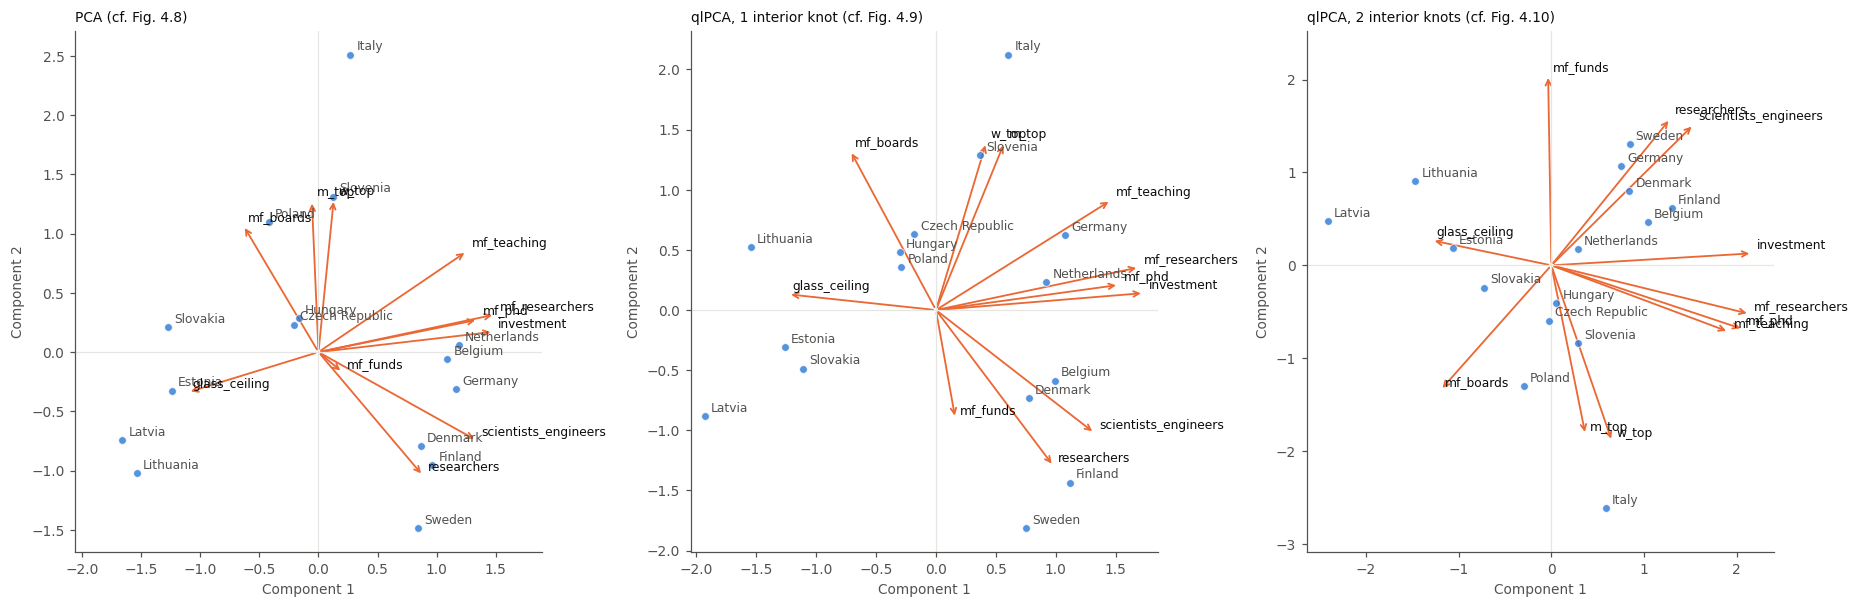

In [12]:
fits = (("PCA (cf. Fig. 4.8)", pca2), ("qlPCA, 1 interior knot (cf. Fig. 4.9)", leg["qlpca1"]), ("qlPCA, 2 interior knots (cf. Fig. 4.10)", leg["qlpca2"]))
aligned = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (title, mdl) in zip(axes, fits):
    aligned[title] = mdl.scores_
    biplot(mdl, names=names, labels=countries, ax=ax)
    ax.set_title(title, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

The thesis identifies three well-separated groups of countries in all three biplots: a left group (Latvia, Lithuania, Estonia, Slovakia), a central group (Slovenia, Poland, Hungary, Czech Republic)
— Italy is not part of it — and a right group (Sweden, Denmark, Finland, Belgium, Germany, Netherlands), the Netherlands leaving the right group in the two-knot biplot. The check below uses
the sign pattern of the scores described in the text (left: negative on both components; central: positive on the second; right: positive on the first and negative on the second). The orientation of a component is arbitrary, so the check is also shown for the orientation that matches the description best. For the two-knot solution the orientation of component 2 follows
from the sign of the V-shaped `mf_funds`, which is arbitrary (§3: the package and the thesis oriented that variable in opposite ways): the thesis's component 2 for two knots is the package's with the opposite sign.

In [13]:
groups = {"left": ["Latvia", "Lithuania", "Estonia", "Slovakia"], "central": ["Slovenia", "Poland", "Hungary", "Czech Republic"],
          "right": ["Sweden", "Denmark", "Finland", "Belgium", "Germany", "Netherlands"]}
patterns = {"left": lambda s: (s[:, 0] < 0) & (s[:, 1] < 0), "central": lambda s: s[:, 1] > 0, "right": lambda s: (s[:, 0] > 0) & (s[:, 1] < 0)}
idx = lambda g: [countries.index(c) for c in groups[g]]

def follows(S):
    return [int(patterns[g](S[idx(g)]).sum()) for g in groups]

for title, S in aligned.items():
    print(title)
    print("   as returned by the package (left, central, right):", follows(S), "of [4, 4, 6]")
    best = max(itertools.product((1, -1), repeat=2), key=lambda sg: sum(follows(S * np.array(sg))))
    if best != (1, 1):
        print(f"   with component signs {best} (an equally valid orientation):", follows(S * np.array(best)), "of [4, 4, 6]")

PCA (cf. Fig. 4.8)
   as returned by the package (left, central, right): [3, 4, 5] of [4, 4, 6]
qlPCA, 1 interior knot (cf. Fig. 4.9)
   as returned by the package (left, central, right): [3, 4, 4] of [4, 4, 6]
qlPCA, 2 interior knots (cf. Fig. 4.10)
   as returned by the package (left, central, right): [1, 0, 0] of [4, 4, 6]
   with component signs (1, -1) (an equally valid orientation): [3, 4, 6] of [4, 4, 6]


## 8 · Piecewise loadings of the V-shaped variables

For a V-shaped transformation the thesis (§3.1.4 E and §4.2.2) notes that the correlation of the first segment of the original variable with the components has the **opposite sense** to that of the transformed variable. The precise statement is about the *same segment*: on a segment with negative slope, $\operatorname{corr}(x_s,h_j)=-\operatorname{corr}(x_s,f_j)$ for the truncated vectors. That is not the same as comparing with the overall loading, which uses all observations, so the signs below need not simply be opposite to the loading; the thesis itself adds that keeping or reversing the sign by segment implies no pattern in intensity.

In [14]:
pl = piecewise_loadings(m1, X)
for nm in ("mf_funds", "w_top", "m_top"):
    j = names.index(nm); d = pl[j]
    print(f"{nm}: loading of the transformed variable {m1.loadings_[j]}")
    for i in range(len(d["edges"]) - 1):
        print(f"   [{d['edges'][i]:6.2f}, {d['edges'][i + 1]:6.2f}]  n={d['n'][i]:2d}  slope {'+' if d['slope_sign'][i] > 0 else '-'}  piecewise loadings {d['loadings'][i]}")

mf_funds: loading of the transformed variable [ 0.087 -0.489]
   [ -4.75,   1.09]  n= 8  slope -  piecewise loadings [-0.077  0.325]
   [  1.09,   6.10]  n= 8  slope +  piecewise loadings [ 0.134 -0.599]
w_top: loading of the transformed variable [0.227 0.755]
   [  1.80,   4.20]  n= 8  slope -  piecewise loadings [ 0.242 -0.749]
   [  4.20,  16.50]  n= 8  slope +  piecewise loadings [0.495 0.78 ]
m_top: loading of the transformed variable [0.309 0.754]
   [  9.80,  17.80]  n= 8  slope -  piecewise loadings [-0.158 -0.654]
   [ 17.80,  38.30]  n= 8  slope +  piecewise loadings [0.34 0.81]


## 9 · Summary of the comparison with the thesis

Largest absolute difference between computed and printed values (`legacy=True`; loadings in absolute value). The thesis prints two or three decimals, so a difference of 0.005 is
rounding.

In [15]:
print(f"{'thesis table':44s} {'max |diff|':>10s}   within tolerance 0.005")
for k, v in SUMMARY.items():
    print(f"{k:44s} {v:10.4f}   {'yes' if v <= TOL + 1e-9 else 'no (see text)'}")

thesis table                                 max |diff|   within tolerance 0.005
Table 4.1 (summary statistics)                   0.0201   no (see text)
Table 4.3 (PCA eigenvalues)                      0.0006   yes
Table 4.4 (PCA loadings, |.|)                    0.0047   yes
Table 4.5 qlpca1 (eigenvalues)                   0.0004   yes
Table 4.6 qlpca1 (|loadings|)                    0.0049   yes
Tables 4.7/4.8 qlpca1 (communalities)            0.0050   yes
Table 4.5 qlpca2 (eigenvalues)                   0.0008   yes
Table 4.6 qlpca2 (|loadings|)                    0.0050   yes
Tables 4.7/4.8 qlpca2 (communalities)            0.0030   yes


**Reproduced** (within printed precision): Tables 4.3, 4.5, 4.6 (absolute values), 4.7, 4.8 and the communality of `mf_funds` in PCA (0.0244 in the thesis is computed from the rounded loadings of Table 4.4, $0.12^2+0.10^2$; with the exact loadings it is 0.0252); Table 4.1 up to the rounding of one mean;
the qualitative description of the transformations, scree plots and biplots, with the caveats below.

**Not reproduced exactly / convention-dependent**

* **Signs of loadings** (Tables 4.4, 4.6): a convention. After aligning signs the values agree. The thesis reads the sign change of `mf_funds` between one and two knots (p. 92) as substantive;
  for a V-shaped transformation $\operatorname{corr}(f_j,h_j)$ is close to zero and the sign is fragile (docs/SPEC.md §8, DESIGN D6).
* **Figure 4.5** (two knots, three components): start-dependent (§6). Both local optima are reported; the default estimator keeps the better one (90.30 %).
* The pseudo-indicator matrices of thesis pp. 52–53 (notebook 01) and the CATPCA/SPSS comparisons (notebook 03) are not reproduced.

## References

* `lavado2012phd` — N. Lavado, PhD thesis, ISCTE-IUL, 2012. Chapter 4 (Tables 4.1–4.8, Figs 4.1–4.10), Appendix A.1.
* `oliveira2009segmentation` — Oliveira & Carvalho (2009), source of the data (provided by the authors; check before redistributing, data/README.md).
* `ec2006shefigures` — European Commission, *She Figures 2006: Women and Science, Statistics and Indicators*.